In [1]:
%pip install requests beautifulsoup4 pandas matplotlib

### Mission 1: Reconnaissance

I inspected the Books to Scrape website using the browser's Inspect tool to understand how the book information is stored in HTML.

1. **Book Title:** The title is inside the `<a>` tag within the `<h3>` tag. I can extract it using `find("h3").find("a")["title"]`.

2. **Price:** The price is displayed below the book title in green text. I will use `.get_text(strip=True)` to extract the price as text and then convert it into a numeric value for analysis.

3. **Rating:** The rating is stored in the CSS class of a paragraph with the class `star-rating`. For example, the class may contain the word `Three`, which represents a three-star rating.

4. **Availability:** The availability information is displayed below the price. I will extract its text using `.get_text(strip=True)` to identify whether the book is in stock.

By inspecting these elements, I can identify the information needed to collect book titles, prices, ratings, and availability from the website.

**Mission 2: Capture the data**

In [2]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
from urllib.parse import urljoin

In [3]:
url = "https://books.toscrape.com/"

response = requests.get(url, timeout=20)

response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

first_page_books = []

for book in soup.select("article.product_pod"):

    title_element = book.select_one("h3 a")
    title = title_element["title"].strip()

    price_text = book.select_one("p.price_color").get_text(strip=True)
    price = float(
        price_text.replace("£", "").replace("Â", "").strip()
    )

    rating_class = book.select_one("p.star-rating")["class"]
    rating_word = next(
        word for word in rating_class if word in rating_map
    )
    rating = rating_map[rating_word]

    availability = book.select_one(
        "p.instock.availability"
    ).get_text(" ", strip=True)

    first_page_books.append({
        "Title": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability
    })

first_page_df = pd.DataFrame(first_page_books)

print("Number of books scraped:", len(first_page_df))
display(first_page_df.head(10))

Number of books scraped: 20


,Title,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock
5,The Requiem Red,22.65,1,In stock
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4,In stock
7,The Coming Woman: A Novel Based on the Life of...,17.93,3,In stock
8,The Boys in the Boat: Nine Americans and Their...,22.60,4,In stock
9,The Black Maria,52.15,1,In stock


In [4]:
print("Column names:")
print(first_page_df.columns.tolist())

print("\nMissing values:")
print(first_page_df.isnull().sum())

print("\nData types:")
print(first_page_df.dtypes)

print("\nRating values found:")
print(sorted(first_page_df["Rating"].unique()))

Column names:
['Title', 'Price', 'Rating', 'Availability']

Missing values:
Title           0
Price           0
Rating          0
Availability    0
dtype: int64

Data types:
Title            object
Price           float64
Rating            int64
Availability     object
dtype: object

Rating values found:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


**Mission 3 — Scale the operation**

In [6]:
def scrape_books_page(page_url):
    """
    Scrape book details from one catalogue page.
    Returns a list of dictionaries.
    """

    response = requests.get(page_url, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    rating_map = {
        "One": 1,
        "Two": 2,
        "Three": 3,
        "Four": 4,
        "Five": 5
    }

    books = []

    for book in soup.select("article.product_pod"):

        title_element = book.select_one("h3 a")
        title = title_element.get("title", "").strip()

        price_element = book.select_one("p.price_color")
        price_text = price_element.get_text(strip=True)
        price = float(
            price_text.replace("£", "").replace("Â", "").strip()
        )

        rating_element = book.select_one("p.star-rating")
        rating_classes = rating_element.get("class", [])

        rating_word = next(
            (word for word in rating_classes if word in rating_map),
            None
        )

        if rating_word is None:
            raise ValueError(f"Unknown rating for book: {title}")

        rating = rating_map[rating_word]

        availability_element = book.select_one(
            "p.instock.availability"
        )
        availability = availability_element.get_text(
            " ", strip=True
        )

        relative_url = title_element.get("href", "")
        product_url = urljoin(page_url, relative_url)

        books.append({
            "Title": title,
            "Price": price,
            "Rating": rating,
            "Availability": availability,
            "Product_URL": product_url
        })

    return books

In [7]:
base_url = "https://books.toscrape.com/"

number_of_pages = 5

all_books = []

for page_number in range(1, number_of_pages + 1):

    if page_number == 1:
        page_url = base_url
    else:
        page_url = (
            f"https://books.toscrape.com/catalogue/page-{page_number}.html"
        )

    page_books = scrape_books_page(page_url)

    all_books.extend(page_books)

    print(
        f"Page {page_number}: {len(page_books)} books collected"
    )

books_df = pd.DataFrame(all_books)

print("\nTotal books scraped:", len(books_df))
display(books_df.head())

Page 1: 20 books collected
Page 2: 20 books collected
Page 3: 20 books collected
Page 4: 20 books collected
Page 5: 20 books collected

Total books scraped: 100


,Title,Price,Rating,Availability,Product_URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [8]:
books_df["Title"] = books_df["Title"].str.strip()

books_df["Price"] = pd.to_numeric(
    books_df["Price"], errors="coerce"
)

books_df["Rating"] = pd.to_numeric(
    books_df["Rating"], errors="coerce"
).astype("Int64")

books_df["Availability"] = (
    books_df["Availability"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

books_df = books_df.drop_duplicates(
    subset=["Title", "Product_URL"]
).reset_index(drop=True)

print("Dataset shape:", books_df.shape)
print("\nMissing values:")
print(books_df.isnull().sum())

print("\nData types:")
print(books_df.dtypes)

print("\nRating range:")
print(books_df["Rating"].min(), "to", books_df["Rating"].max())

print("\nDuplicate product URLs:", books_df["Product_URL"].duplicated().sum())

display(books_df.head(10))

Dataset shape: (100, 5)

Missing values:
Title           0
Price           0
Rating          0
Availability    0
Product_URL     0
dtype: int64

Data types:
Title            object
Price           float64
Rating            Int64
Availability     object
Product_URL      object
dtype: object

Rating range:
1 to 5

Duplicate product URLs: 0


,Title,Price,Rating,Availability,Product_URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,22.65,1,In stock,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4,In stock,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,17.93,3,In stock,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,22.60,4,In stock,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,52.15,1,In stock,https://books.toscrape.com/catalogue/the-black...


In [9]:
csv_filename = "competitor_books.csv"

books_df.to_csv(
    csv_filename,
    index=False,
    encoding="utf-8-sig"
)

print("CSV successfully saved:", csv_filename)
print("Records saved:", len(books_df))

CSV successfully saved: competitor_books.csv
Records saved: 100


In [10]:
check_df = pd.read_csv("competitor_books.csv")

print("CSV read successfully.")
print("Rows:", len(check_df))
print("Columns:", check_df.columns.tolist())

display(check_df.head())

CSV read successfully.
Rows: 100
Columns: ['Title', 'Price', 'Rating', 'Availability', 'Product_URL']


,Title,Price,Rating,Availability,Product_URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


**BONUS**

In [11]:
from urllib.parse import urljoin
import time

current_url = "https://books.toscrape.com/"
all_catalogue_books = []
visited_pages = set()

while current_url and current_url not in visited_pages:

    visited_pages.add(current_url)

    response = requests.get(current_url, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    page_books = scrape_books_page(current_url)
    all_catalogue_books.extend(page_books)

    print(
        f"Page {len(visited_pages)} scraped | "
        f"Books collected: {len(all_catalogue_books)}"
    )

    next_link = soup.select_one("li.next a")

    if next_link:
        current_url = urljoin(current_url, next_link["href"])
        time.sleep(0.2)
    else:
        current_url = None

all_books_df = pd.DataFrame(all_catalogue_books)

all_books_df = all_books_df.drop_duplicates(
    subset=["Title", "Product_URL"]
).reset_index(drop=True)

all_books_df.to_csv(
    "competitor_books_all_pages.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nBoss level complete!")
print("Pages visited:", len(visited_pages))
print("Unique books collected:", len(all_books_df))

display(all_books_df.head())

Page 1 scraped | Books collected: 20
Page 2 scraped | Books collected: 40
Page 3 scraped | Books collected: 60
Page 4 scraped | Books collected: 80
Page 5 scraped | Books collected: 100
Page 6 scraped | Books collected: 120
Page 7 scraped | Books collected: 140
Page 8 scraped | Books collected: 160
Page 9 scraped | Books collected: 180
Page 10 scraped | Books collected: 200
Page 11 scraped | Books collected: 220
Page 12 scraped | Books collected: 240
Page 13 scraped | Books collected: 260
Page 14 scraped | Books collected: 280
Page 15 scraped | Books collected: 300
Page 16 scraped | Books collected: 320
Page 17 scraped | Books collected: 340
Page 18 scraped | Books collected: 360
Page 19 scraped | Books collected: 380
Page 20 scraped | Books collected: 400
Page 21 scraped | Books collected: 420
Page 22 scraped | Books collected: 440
Page 23 scraped | Books collected: 460
Page 24 scraped | Books collected: 480
Page 25 scraped | Books collected: 500
Page 26 scraped | Books collected: 520

,Title,Price,Rating,Availability,Product_URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


**Mission 4 — Intelligence analysis**

In [12]:
analysis_df = all_books_df.copy()

valid_prices = analysis_df.dropna(subset=["Price"])
valid_ratings = analysis_df.dropna(subset=["Rating"])

most_expensive = valid_prices.loc[
    valid_prices["Price"].idxmax()
]

print("1. Most expensive book:")
print("Title:", most_expensive["Title"])
print(f"Price: £{most_expensive['Price']:.2f}")

cheapest = valid_prices.loc[
    valid_prices["Price"].idxmin()
]

print("\n2. Cheapest book:")
print("Title:", cheapest["Title"])
print(f"Price: £{cheapest['Price']:.2f}")

average_price = valid_prices["Price"].mean()

print("\n3. Average book price:")
print(f"£{average_price:.2f}")

five_star_books = valid_ratings[
    valid_ratings["Rating"] == 5
]

print("\n4. Number of five-star books:")
print(len(five_star_books))

in_stock_mask = (
    analysis_df["Availability"]
    .str.contains("In stock", case=False, na=False)
)

in_stock_count = int(in_stock_mask.sum())
total_books = len(analysis_df)

in_stock_percentage = (
    in_stock_count / total_books * 100
    if total_books else 0
)

print("\n5. Percentage of books in stock:")
print(f"{in_stock_percentage:.2f}%")
print(f"In stock: {in_stock_count} out of {total_books}")

top_five = (
    valid_ratings
    .sort_values(
        ["Rating", "Price", "Title"],
        ascending=[False, True, True]
    )
    .head(5)
)

print("\n6. Top five highest-rated books:")
display(top_five[
    ["Title", "Price", "Rating", "Availability"]
])

if not five_star_books.empty:
    cheapest_five_star = five_star_books.loc[
        five_star_books["Price"].idxmin()
    ]

    print("\n7. Cheapest five-star book:")
    print("Title:", cheapest_five_star["Title"])
    print(f"Price: £{cheapest_five_star['Price']:.2f}")
else:
    print("\n7. No five-star books were found in this dataset.")

1. Most expensive book:
Title: The Perfect Play (Play by Play #1)
Price: £59.99

2. Cheapest book:
Title: An Abundance of Katherines
Price: £10.00

3. Average book price:
£35.07

4. Number of five-star books:
196

5. Percentage of books in stock:
100.00%
In stock: 1000 out of 1000

6. Top five highest-rated books:


,Title,Price,Rating,Availability
638,An Abundance of Katherines,10.00,5,In stock
302,Greek Mythic History,10.23,5,In stock
590,The Power Greens Cookbook: 140 Delicious Super...,11.05,5,In stock
316,Dear Mr. Knightley,11.21,5,In stock
601,The Darkest Corners,11.33,5,In stock



7. Cheapest five-star book:
Title: An Abundance of Katherines
Price: £10.00


In [13]:
summary = pd.DataFrame({
    "Business Question": [
        "Most expensive book",
        "Cheapest book",
        "Average book price",
        "Number of five-star books",
        "Books in stock",
        "Percentage in stock",
        "Cheapest five-star book"
    ],
    "Answer": [
        f"{most_expensive['Title']} (£{most_expensive['Price']:.2f})",
        f"{cheapest['Title']} (£{cheapest['Price']:.2f})",
        f"£{average_price:.2f}",
        str(len(five_star_books)),
        f"{in_stock_count} out of {total_books}",
        f"{in_stock_percentage:.2f}%",
        (
            f"{cheapest_five_star['Title']} "
            f"(£{cheapest_five_star['Price']:.2f})"
            if not five_star_books.empty
            else "No five-star books found"
        )
    ]
})

display(summary)

,Business Question,Answer
0,Most expensive book,The Perfect Play (Play by Play #1) (£59.99)
1,Cheapest book,An Abundance of Katherines (£10.00)
2,Average book price,£35.07
3,Number of five-star books,196
4,Books in stock,1000 out of 1000
5,Percentage in stock,100.00%
6,Cheapest five-star book,An Abundance of Katherines (£10.00)


Bonus 3 — Count books at each rating level

In [14]:
rating_counts = (
    analysis_df["Rating"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .sort_index()
)

rating_summary = pd.DataFrame({
    "Rating": [1, 2, 3, 4, 5],
    "Number_of_Books": rating_counts.values
})

display(rating_summary)

,Rating,Number_of_Books
0,1,226
1,2,196
2,3,203
3,4,179
4,5,196


Bonus 4 — Create a bar chart of rating counts


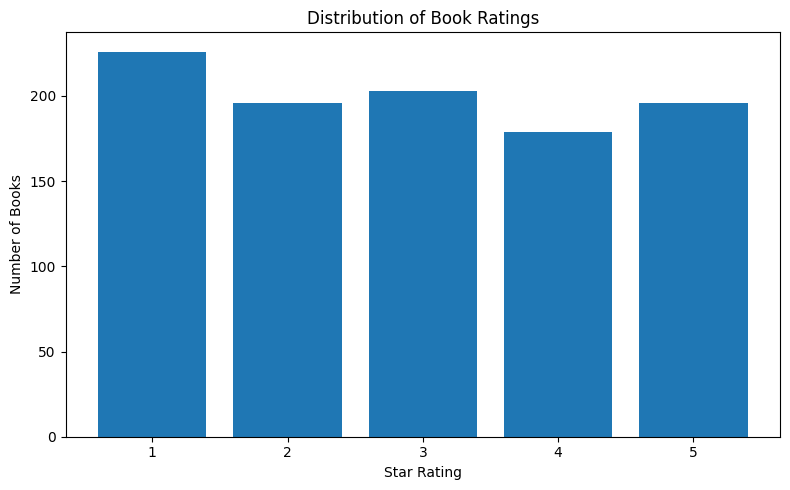

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    rating_summary["Rating"].astype(str),
    rating_summary["Number_of_Books"]
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.xticks(["1", "2", "3", "4", "5"])

plt.tight_layout()
plt.show()

Explanation: The x-axis represents star-rating levels from 1 to 5, while the y-axis represents the number of books in each category. The tallest bar identifies the most common rating in scraped catalogue.

Final Challenge — The CEO has £100

In [16]:
import numpy as np

ceo_df = analysis_df.dropna(
    subset=["Title", "Price", "Rating"]
).copy()


ceo_df = ceo_df[
    (ceo_df["Price"] > 0) &
    (ceo_df["Rating"].between(1, 5)) &
    (ceo_df["Price"] <= 100)
].reset_index(drop=True)

ceo_df["Cost_Pence"] = (
    (ceo_df["Price"] * 100).round().astype(int)
)

budget_pence = 10000
number_of_books = len(ceo_df)

dp = np.zeros(budget_pence + 1, dtype=int)

take = np.zeros(
    (number_of_books, budget_pence + 1),
    dtype=bool
)

for i, book in ceo_df.iterrows():

    cost = int(book["Cost_Pence"])
    rating = int(book["Rating"])

    if cost > budget_pence:
        continue


    candidate = dp[:-cost] + rating
    current = dp[cost:]

    improve = candidate > current

    take[i, cost:] = improve
    dp[cost:][improve] = candidate[improve]

best_rating_score = int(dp[budget_pence])

selected_indices = []
remaining_budget = budget_pence

for i in range(number_of_books - 1, -1, -1):

    if take[i, remaining_budget]:
        selected_indices.append(i)
        remaining_budget -= int(ceo_df.loc[i, "Cost_Pence"])

selected_indices.reverse()

selected_books = ceo_df.iloc[selected_indices].copy()

ceo_result = selected_books[
    ["Title", "Price", "Rating"]
].copy()

ceo_result["Price"] = ceo_result["Price"].round(2)

total_cost = selected_books["Cost_Pence"].sum() / 100
total_rating = int(selected_books["Rating"].sum())

print("CEO £100 MARKET-RESEARCH CHALLENGE")
display(ceo_result)

print(f"Total cost: £{total_cost:.2f}")
print(f"Budget remaining: £{100 - total_cost:.2f}")
print(f"Total rating score: {total_rating}")
print(f"Number of books selected: {len(selected_books)}")

assert total_cost <= 100.00, "Budget exceeded!"
assert total_rating == best_rating_score, "Check the optimization result."

print("Budget constraint verified.")
print("Rating score is optimal for the selected dataset.")

CEO £100 MARKET-RESEARCH CHALLENGE


,Title,Price,Rating
261,Superman Vol. 1: Before Truth (Superman by Gen...,11.89,5
277,Old School (Diary of a Wimpy Kid #10),11.83,5
302,Greek Mythic History,10.23,5
316,Dear Mr. Knightley,11.21,5
501,The Origin of Species,10.01,4
521,"Naturally Lean: 125 Nourishing Gluten-Free, Pl...",11.38,5
535,Every Heart a Doorway (Every Heart A Doorway #1),12.16,5
590,The Power Greens Cookbook: 140 Delicious Super...,11.05,5
638,An Abundance of Katherines,10.00,5


Total cost: £99.76
Budget remaining: £0.24
Total rating score: 44
Number of books selected: 9
Budget constraint verified.
Rating score is optimal for the selected dataset.


In [17]:
ceo_result.to_csv(
    "ceo_100_pound_selection.csv",
    index=False,
    encoding="utf-8-sig"
)

print("CEO selection saved to ceo_100_pound_selection.csv")

print("Total cost:", round(total_cost, 2))
print("Total rating score:", total_rating)
print("Books selected:", len(ceo_result))

CEO selection saved to ceo_100_pound_selection.csv
Total cost: 99.76
Total rating score: 44
Books selected: 9


**Business decision — What books should I prioritize?
Evidence for Recommendation:**

In [18]:
high_rated = analysis_df[
    (analysis_df["Rating"] >= 4) &
    (analysis_df["Availability"].str.contains(
        "In stock", case=False, na=False
    ))
].copy()

high_rated = high_rated.sort_values(
    ["Rating", "Price"],
    ascending=[False, True]
)

print("Number of in-stock books rated 4 or 5:")
print(len(high_rated))

if not high_rated.empty:
    print("\nFive strongest candidates by rating and price:")
    display(high_rated[
        ["Title", "Price", "Rating", "Availability"]
    ].head(5))

    print(
        "\nAverage price of in-stock books rated 4 or 5: "
        f"£{high_rated['Price'].mean():.2f}"
    )

print(
    "\nOverall average book price: "
    f"£{analysis_df['Price'].mean():.2f}"
)

print(
    "\nOverall average rating: "
    f"{analysis_df['Rating'].mean():.2f} stars"
)

Number of in-stock books rated 4 or 5:
375

Five strongest candidates by rating and price:


,Title,Price,Rating,Availability
638,An Abundance of Katherines,10.00,5,In stock
302,Greek Mythic History,10.23,5,In stock
590,The Power Greens Cookbook: 140 Delicious Super...,11.05,5,In stock
316,Dear Mr. Knightley,11.21,5,In stock
601,The Darkest Corners,11.33,5,In stock



Average price of in-stock books rated 4 or 5: £35.72

Overall average book price: £35.07

Overall average rating: 2.92 stars


**Business Recommendation**

Based on the scraped competitor data, I recommend that our online bookstore prioritize highly rated books with competitive prices and confirmed in-stock status. The data shows that **375** in-stock books have ratings of 4 or 5 stars, providing a starting shortlist of products to investigate. Furthermore, the average price of these books is **£35.72**, compared with the overall average book price of **£35.07**. We should test a selection of these products, monitor actual customer demand and sales, and adjust our product range and pricing based on the results.

In [19]:
import os

files_to_check = [
    "competitor_books.csv",
    "competitor_books_all_pages.csv",
    "ceo_100_pound_selection.csv"
]

for filename in files_to_check:
    if os.path.exists(filename):
        print(f"Found: {filename}")
    else:
        print(f"Not found: {filename}")

Found: competitor_books.csv
Found: competitor_books_all_pages.csv
Found: ceo_100_pound_selection.csv


In [20]:
from google.colab import files

files.download("competitor_books.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
files.download("competitor_books_all_pages.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
files.download("ceo_100_pound_selection.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>